## Week 6 

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [64]:
df1_animation = pd.read_csv("data/Animation_Movies_clean.csv")


In [65]:
df1_animation["log_budget"] = np.where(
    df1_animation["budget"] > 0,
    np.log10(df1_animation["budget"]),
    np.nan
)

df1_animation["log_popularity"] = np.where(
    df1_animation["popularity"] > 0,
    np.log10(df1_animation["popularity"]),
    np.nan
)

df1_animation["log_revenue"] = np.where(
    df1_animation["revenue"] > 0,
    np.log10(df1_animation["revenue"]),
    np.nan
)

/usr/local/python/3.14.2/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [66]:
animation_week6 = df1_animation.dropna(
    subset=[
        "log_budget",
        "log_popularity",
        "vote_average",
        "vote_count",
        "runtime",
        "log_revenue"
    ]
).copy()

animation_week6.shape

(616, 23)

In [67]:
revenue_median = animation_week6[
    "log_revenue"
].median()

animation_week6["high_revenue"] = (
    animation_week6["log_revenue"] > revenue_median
).astype(int)

In [68]:
animation_week6["high_revenue"].value_counts()

high_revenue
1    308
0    308
Name: count, dtype: int64

In [69]:
features = [
    "log_budget",
    "log_popularity",
    "vote_average",
    "vote_count",
    "runtime"
]

X = animation_week6[features]

y = animation_week6["high_revenue"]

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Decicion Tree

In [71]:
tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

y_pred_tree = tree_model.predict(
    X_test
)

In [72]:
tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print(
    "Decision Tree Accuracy:",
    tree_accuracy
)

Decision Tree Accuracy: 0.8629032258064516


In [73]:
tree_cm = confusion_matrix(
    y_test,
    y_pred_tree
)

tree_cm

array([[52, 10],
       [ 7, 55]])

In [74]:
print(
    classification_report(
        y_test,
        y_pred_tree
    )
)

              precision    recall  f1-score   support

           0       0.88      0.84      0.86        62
           1       0.85      0.89      0.87        62

    accuracy                           0.86       124
   macro avg       0.86      0.86      0.86       124
weighted avg       0.86      0.86      0.86       124



In [75]:
tree_importance = pd.DataFrame({
    "Feature": features,
    "Importance": tree_model.feature_importances_
})

tree_importance.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
1,log_popularity,0.733857
0,log_budget,0.105360
3,vote_count,0.101117
4,runtime,0.033112
2,vote_average,0.026554


### Random Forest 

In [76]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(
    X_train,
    y_train
)

y_pred_rf = random_forest.predict(
    X_test
)

In [77]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.8790322580645161


In [78]:
rf_cm = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Confusion Matrix:")
print(rf_cm)

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Confusion Matrix:
[[52 10]
 [ 5 57]]
              precision    recall  f1-score   support

           0       0.91      0.84      0.87        62
           1       0.85      0.92      0.88        62

    accuracy                           0.88       124
   macro avg       0.88      0.88      0.88       124
weighted avg       0.88      0.88      0.88       124



In [79]:
rf_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest.feature_importances_
})

rf_importance.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
1,log_popularity,0.307938
3,vote_count,0.287569
0,log_budget,0.256465
4,runtime,0.074446
2,vote_average,0.073581


In [80]:
depth_results = []

for depth in [2, 3, 4, 5, 6, 8, 10, None]:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_accuracy = tree.score(
        X_train,
        y_train
    )

    test_accuracy = tree.score(
        X_test,
        y_test
    )

    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

depth_results = pd.DataFrame(depth_results)

depth_results

,Max Depth,Training Accuracy,Test Accuracy
0,2,0.882114,0.846774
1,3,0.914634,0.862903
2,4,0.930894,0.862903
3,5,0.945122,0.862903
4,6,0.963415,0.862903
5,8,0.987805,0.862903
6,10,0.995935,0.838710
7,None,1.000000,0.846774


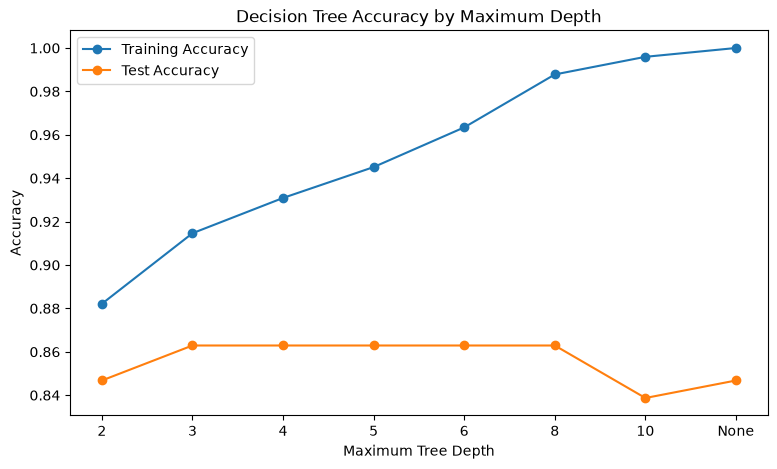

In [81]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_results["Max Depth"],
    depth_results["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["Max Depth"],
    depth_results["Test Accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy by Maximum Depth")

plt.legend()
plt.show()

In [82]:
tree_numbers = [10, 50, 100, 200, 500]

rf_results = []

for n in tree_numbers:

    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    rf.fit(X_train, y_train)

    train_accuracy = rf.score(
        X_train,
        y_train
    )

    test_accuracy = rf.score(
        X_test,
        y_test
    )

    rf_results.append({
        "Number of Trees": n,
        "Training Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

rf_results = pd.DataFrame(rf_results)

rf_results

,Number of Trees,Training Accuracy,Test Accuracy
0,10,0.985772,0.862903
1,50,1.000000,0.895161
2,100,1.000000,0.879032
3,200,1.000000,0.895161
4,500,1.000000,0.887097


In [83]:
final_rf_animation = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

final_rf_animation.fit(
    X_train,
    y_train
)

y_pred_final_rf = final_rf_animation.predict(
    X_test
)

print(
    "Final Random Forest Accuracy:",
    accuracy_score(y_test, y_pred_final_rf)
)

print(
    confusion_matrix(
        y_test,
        y_pred_final_rf
    )
)

print(
    classification_report(
        y_test,
        y_pred_final_rf
    )
)

Final Random Forest Accuracy: 0.8951612903225806
[[53  9]
 [ 4 58]]
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        62
           1       0.87      0.94      0.90        62

    accuracy                           0.90       124
   macro avg       0.90      0.90      0.89       124
weighted avg       0.90      0.90      0.89       124



## Dataframe 2

In [84]:
df2_action = pd.read_csv("data/Action_Movies_clean.csv")

In [85]:
df2_action["log_votes"] = np.where(
    df2_action["votes"] > 0,
    np.log10(df2_action["votes"]),
    np.nan
)

df2_action["log_gross"] = np.where(
    df2_action["gross(in $)"] > 0,
    np.log10(df2_action["gross(in $)"]),
    np.nan
)

In [86]:
action_week6 = df2_action.dropna(
    subset=[
        "log_votes",
        "rating",
        "runtime",
        "year",
        "log_gross"
    ]
).copy()

action_week6.shape

(2758, 16)

In [87]:
gross_median = action_week6[
    "log_gross"
].median()

action_week6["high_gross"] = (
    action_week6["log_gross"] > gross_median
).astype(int)

In [88]:
action_week6["high_gross"].value_counts()

high_gross
1    1379
0    1379
Name: count, dtype: int64

In [89]:
features_action = [
    "log_votes",
    "rating",
    "runtime",
    "year"
]

X_action = action_week6[
    features_action
]

y_action = action_week6[
    "high_gross"
]

In [90]:
X_train_action, X_test_action, y_train_action, y_test_action = train_test_split(
    X_action,
    y_action,
    test_size=0.2,
    random_state=42,
    stratify=y_action
)

In [91]:
tree_action = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree_action.fit(
    X_train_action,
    y_train_action
)

y_pred_tree_action = tree_action.predict(
    X_test_action
)

In [92]:
tree_accuracy_action = accuracy_score(
    y_test_action,
    y_pred_tree_action
)

print(
    "Action Decision Tree Accuracy:",
    tree_accuracy_action
)

Action Decision Tree Accuracy: 0.8605072463768116


In [93]:
print(
    confusion_matrix(
        y_test_action,
        y_pred_tree_action
    )
)

print(
    classification_report(
        y_test_action,
        y_pred_tree_action
    )
)

[[223  53]
 [ 24 252]]
              precision    recall  f1-score   support

           0       0.90      0.81      0.85       276
           1       0.83      0.91      0.87       276

    accuracy                           0.86       552
   macro avg       0.86      0.86      0.86       552
weighted avg       0.86      0.86      0.86       552



In [94]:
tree_importance_action = pd.DataFrame({
    "Feature": features_action,
    "Importance": tree_action.feature_importances_
})

tree_importance_action.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
0,log_votes,0.841999
3,year,0.097246
2,runtime,0.032081
1,rating,0.028674


In [95]:
depth_results_action = []

for depth in [2, 3, 4, 5, 6, 8, 10, None]:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(
        X_train_action,
        y_train_action
    )

    train_accuracy = tree.score(
        X_train_action,
        y_train_action
    )

    test_accuracy = tree.score(
        X_test_action,
        y_test_action
    )

    depth_results_action.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

depth_results_action = pd.DataFrame(
    depth_results_action
)

depth_results_action

,Max Depth,Training Accuracy,Test Accuracy
0,2,0.834995,0.826087
1,3,0.857661,0.849638
2,4,0.874433,0.860507
3,5,0.883500,0.853261
4,6,0.901632,0.855072
5,8,0.936990,0.851449
6,10,0.963735,0.829710
7,None,1.000000,0.818841


In [96]:
rf_action = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_action.fit(
    X_train_action,
    y_train_action
)

y_pred_rf_action = rf_action.predict(
    X_test_action
)

In [97]:
rf_accuracy_action = accuracy_score(
    y_test_action,
    y_pred_rf_action
)

print(
    "Action Random Forest Accuracy:",
    rf_accuracy_action
)

print(
    confusion_matrix(
        y_test_action,
        y_pred_rf_action
    )
)

print(
    classification_report(
        y_test_action,
        y_pred_rf_action
    )
)

Action Random Forest Accuracy: 0.8768115942028986
[[246  30]
 [ 38 238]]
              precision    recall  f1-score   support

           0       0.87      0.89      0.88       276
           1       0.89      0.86      0.88       276

    accuracy                           0.88       552
   macro avg       0.88      0.88      0.88       552
weighted avg       0.88      0.88      0.88       552



In [98]:
rf_importance_action = pd.DataFrame({
    "Feature": features_action,
    "Importance": rf_action.feature_importances_
})

rf_importance_action.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
0,log_votes,0.628008
3,year,0.145107
1,rating,0.115514
2,runtime,0.111372


In [99]:
tree_numbers = [
    10,
    50,
    100,
    200,
    500
]

rf_results_action = []

for n in tree_numbers:

    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    rf.fit(
        X_train_action,
        y_train_action
    )

    train_accuracy = rf.score(
        X_train_action,
        y_train_action
    )

    test_accuracy = rf.score(
        X_test_action,
        y_test_action
    )

    rf_results_action.append({
        "Number of Trees": n,
        "Training Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

rf_results_action = pd.DataFrame(
    rf_results_action
)

rf_results_action

,Number of Trees,Training Accuracy,Test Accuracy
0,10,0.989574,0.860507
1,50,0.998640,0.878623
2,100,1.000000,0.876812
3,200,1.000000,0.880435
4,500,1.000000,0.882246


In [100]:
final_rf_action = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

final_rf_action.fit(
    X_train_action,
    y_train_action
)

y_pred_final_action = final_rf_action.predict(
    X_test_action
)

print(
    "Final Action Random Forest Accuracy:",
    accuracy_score(
        y_test_action,
        y_pred_final_action
    )
)

Final Action Random Forest Accuracy: 0.8822463768115942
